In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import keras
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Flatten, Dense
%matplotlib inline

In [3]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()
x_train.shape, y_train.shape, " ", x_test.shape, y_test.shape

((60000, 28, 28), (60000,), ' ', (10000, 28, 28), (10000,))

In [4]:
# x_train[0] # ! seeing first image

In [5]:
class_labels = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]
# class_labels

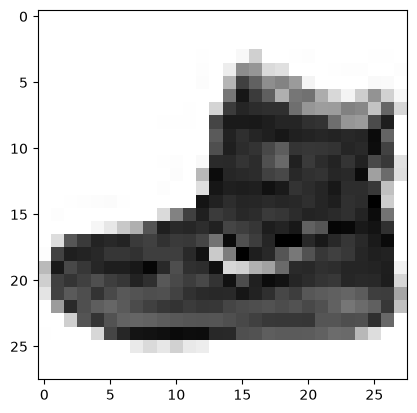

In [6]:
plt.imshow(x_train[0], cmap="Greys") # ! imshow display 2d array as img

In [7]:
x_train.shape

(60000, 28, 28)

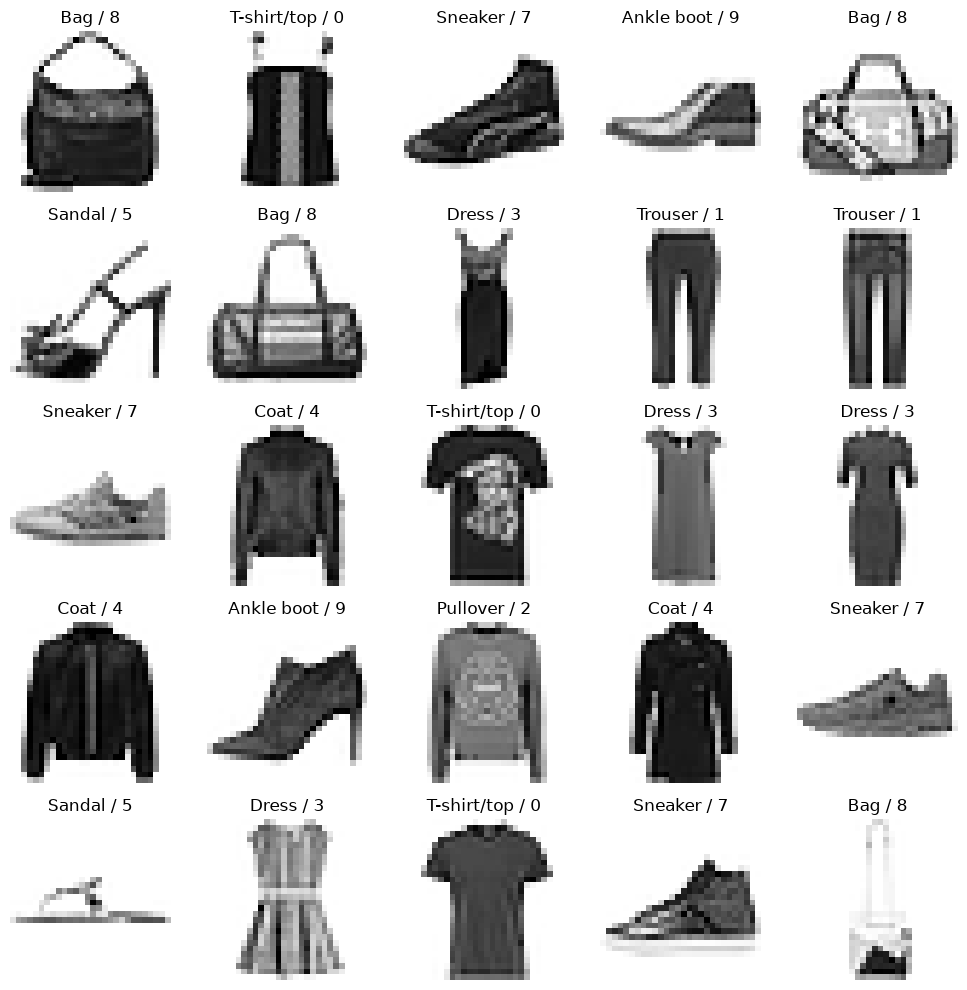

In [38]:
plt.figure(figsize=(10, 10))

for j, i in enumerate(np.random.randint(0, 60000, 25), start=1):
    plt.subplot(5, 5, j)
    plt.imshow(x_train[i].squeeze(), cmap="Greys")
    plt.axis("off")
    plt.title(f"{class_labels[y_train[i]]} / {y_train[i]}")

plt.tight_layout()
plt.show()

In [ ]:
x_train.ndim

3

In [9]:
x_train = np.expand_dims(x_train, -1)
x_test = np.expand_dims(x_test, -1)

# * Before	        After
# * (60000, 28, 28)	(60000, 28, 28, 1)
# * (10000, 28, 28)	(10000, 28, 28, 1)

# ! Why is this required? Your Conv2D layer expects image batches in the format (batch_size, height, width, channels) under the default TensorFlow data format.

x_train.ndim

4

In [41]:
x_train = x_train/255
x_test = x_test/255

In [ ]:
from sklearn.model_selection import train_test_split

x_train, x_validation, y_train, y_validation = train_test_split(x_train, y_train)
x_train.shape, y_train.shape, x_validation.shape, y_validation.shape

((45000, 28, 28, 1), (45000,), (15000, 28, 28, 1), (15000,))

In [ ]:
cnn = keras.models.Sequential([
    tf.keras.layers.Conv2D(filters = 32, kernel_size = 3, strides = (1, 1), padding = 'valid', activation = 'relu', input_shape = (28, 28, 1)),
    tf.keras.layers.MaxPooling2D((2, 2)),
    
    tf.keras.layers.Conv2D(filters = 64, kernel_size = 3, strides = (2, 2), padding = 'same', activation = 'relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
                           
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation = 'relu'),
    tf.keras.layers.Dropout(0.25),
    tf.keras.layers.Dense(256, activation = 'relu'),
    tf.keras.layers.Dropout(0.25),
    tf.keras.layers.Dense(128, activation = 'relu'),
    tf.keras.layers.Dense(10, activation = 'softmax'),
])

In [ ]:
cnn.compile(optimizer = 'adam', loss = 'sparse_categorical_crossentropy',
           metrics = ['accuracy'])
cnn.fit(x_train, y_train, epochs = 20, batch_size = 16, verbose = 1,
       validation_data = (x_validation, y_validation))

W0000 00:00:1792517052.508756   16256 cpu_allocator_impl.cc:174] Allocation of 141120000 exceeds 10% of free system memory.


Epoch 1/20
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 24s 8ms/step - accuracy: 0.7910 - loss: 0.5619 - val_accuracy: 0.8641 - val_loss: 0.3683
Epoch 2/20
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 21s 7ms/step - accuracy: 0.8639 - loss: 0.3679 - val_accuracy: 0.8698 - val_loss: 0.3477
Epoch 3/20
2801/2813 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8826 - loss: 0.3212

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9012 - loss: 0.3086


Text(0.5, 1.0, 'Coat / 3')

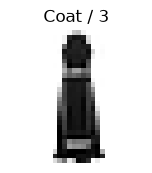

In [ ]:
y_pred = cnn.predict(x_test)

cnn.evaluate(x_test, y_test)

plt.figure(figsize = (10, 10))
j = 1
for i in np.random.randint(0, 1000, 25):
    plt.subplot(5, 5, j)
j += 1
plt.imshow(x_train[i], cmap = 'Greys')
plt.axis('off')
plt.title('{} / {}'.format(class_labels[y_train[i]], y_train[i]))

In [ ]:
print("vishal")

vishal
